# Day 39 | Let an Agent Search Documents

**KGP Talkie**

Wrap retrieval as a tool and check when the agent uses it.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

The supplied course uses these v1 interfaces. We keep their version notices out of the classroom display; real input, validation, and server errors still appear.

In [2]:
import warnings
warnings.filterwarnings("ignore", message=".*langchain-community.*sunset.*", category=DeprecationWarning)
warnings.filterwarnings("ignore", message="The class `InMemoryChatMessageHistory` was deprecated.*")

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [3]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [4]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

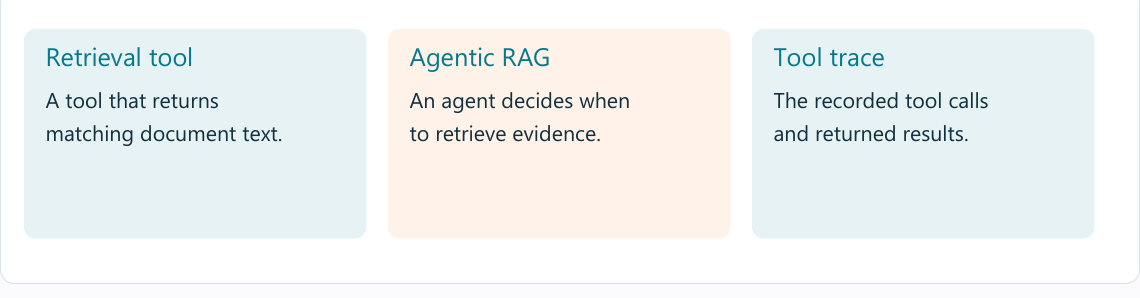

Document keeps text and source details. OllamaEmbeddings returns vectors, not chat replies.

In [5]:
from langchain_core.documents import Document
from langchain_ollama import OllamaEmbeddings

FAISS stores vectors and finds nearby vectors. Its result is linked back to source text.

In [6]:
from langchain_community.vectorstores import FAISS

One fact per line keeps the first search example easy to inspect.

In [7]:
lines = (ASSETS / "course-notes.txt").read_text(encoding="utf-8").splitlines()

enumerate gives a line position. The list creates one Document per line and keeps an evidence label.

In [8]:
docs = [Document(page_content=line, metadata={"source": "course-notes.txt", "line": i + 1}) for i, line in enumerate(lines)]

Use the same downloaded embedding model for stored facts and questions.

In [9]:
embeddings = OllamaEmbeddings(model="nomic-embed-text", base_url="http://localhost:11434")

Embed each document and build this notebook's own index. No previous day is required.

In [10]:
store = FAISS.from_documents(docs, embeddings)

ChatOllama sends chat requests to the local Ollama server.

In [11]:
from langchain_ollama import ChatOllama

We keep tracing off for the local lesson. KGP_MODEL lets us choose another installed chat tag; llama3.2 is the tested default.

In [12]:
os.environ["LANGSMITH_TRACING"] = "false"
MODEL = os.getenv("KGP_MODEL", "llama3.2")

Temperature 0 reduces varied choices. The 128-token cap keeps this small task short; it does not guarantee correctness. localhost means this computer.

In [13]:
llm = ChatOllama(model=MODEL, temperature=0, num_predict=128, base_url="http://localhost:11434", client_kwargs={"timeout": 180})

In [14]:
from langchain_core.tools import tool
from langchain.agents import create_agent

In [15]:
@tool
def find_course_fact(question: str) -> str:
    """Search local workshop notes for a timetable, room, or laptop fact."""
    found = store.similarity_search(question, k=3)
    return "\n".join(f"Line {doc.metadata['line']}: {doc.page_content}" for doc in found)

In [16]:
agent = create_agent(llm, [find_course_fact], system_prompt="For workshop facts, use find_course_fact. Answer only from its results and keep line labels. If missing, say not provided.")

In [17]:
result = agent.invoke({"messages": [{"role": "user", "content": "When is Pandas class?"}]}, config={"recursion_limit": 10})

In [18]:
[(m.type, m.content, getattr(m, "tool_calls", [])) for m in result["messages"]]

[('human', 'When is Pandas class?', []),
 ('ai',
  '',
  [{'name': 'find_course_fact',
    'args': {'question': 'When is Pandas class?'},
    'id': 'ec37a63b-82c9-4543-987d-47ce54d75f69',
    'type': 'tool_call'}]),
 ('tool',
  'Line 2: Pandas class is on Tuesday at 11:00 in Room 3.\nLine 1: Python class is on Monday at 10:00 in Room 2.\nLine 3: Bring a laptop to both classes.',
  []),
 ('ai', 'The Pandas class is on Tuesday at 11:00 in Room 3.', [])]

In [19]:
fresh = agent.invoke({"messages": [{"role": "user", "content": "What is the course fee?"}]}, config={"recursion_limit": 10})

In [20]:
print(fresh["messages"][-1].content)

Unfortunately, the course fee is not provided in the available information.


In [21]:
greeting = agent.invoke({"messages": [{"role": "user", "content": "Hello."}]}, config={"recursion_limit": 10})
print(greeting["messages"][-1].content)

Not provided


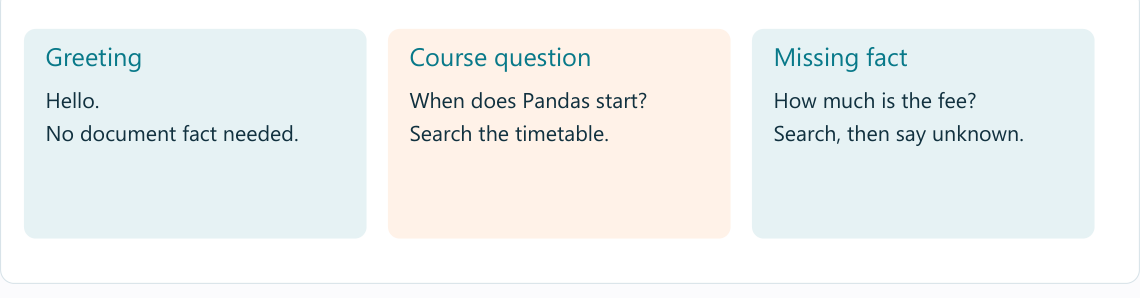

## Try a fresh input

Test a greeting, a supported question, and a missing fact. Check the tool trace for each.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/langchain-agentic-rag).